## UCI Human Activity Recognition (HAR) — Classical ML Pipeline
Data loading & EDA
Preprocessing
multiple model training and comparison
tuning
evaluation

<div class="alert alert-block alert-info" style="border-left: 6px solid #2196F3; padding: 15px;">
    <h3 style="margin-top:0; color:#0b51c5;"> Dataset Profile: Human Activity Recognition Using Smartphones (HAR)</h3>
    The HAR dataset classifies human activities using 3D sensor data collected from a waist-mounted smartphone, capturing precise body motion patterns during daily routines.
</div>

###  Experimental Setup
* **Participants:** **30 volunteers** aged 19–48 years.
* **Target Classes:** **6 target activities** split across dynamic and static motions:
  * `WALKING`
  * `WALKING_UPSTAIRS`
  * `WALKING_DOWNSTAIRS`
  * `SITTING`
  * `STANDING`
  * `LAYING`

---

### Device & Signal Specifications

| Parameter | Specification | Details |
| :--- | :--- | :--- |
| **Hardware** | Samsung Galaxy S II | Worn on the participant's waist |
| **Sampling Rate** | **50 Hz** | Captures 50 data samples every second |
| **Accelerometer** | 3D Linear Acceleration | Measures motion forces along $X, Y, Z$ axes (includes gravity) |
| **Gyroscope** | 3D Angular Velocity | Measures rotational speed around $X, Y, Z$ axes |

> **Data Windowing:** The raw signals were pre-segmented into **sliding windows of 2.56 seconds** with a **50% overlap**, yielding exactly **128 readings per window** ($2.56s \times 50Hz$).

In [1]:
from pathlib import Path
path = data_dir = Path('../../data/open datasets/UCI HAR Dataset')
print("Path to dataset files:", path)

Path to dataset files: ..\..\data\open datasets\UCI HAR Dataset


## Setup environment

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.fft import rfft, rfftfreq
import pywt
import itertools

from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler


## Load dataset

In [4]:
X_train = pd.read_csv(path / 'train/X_train.txt',sep=r'\s+', header = None)
y_train = pd.read_csv(path / 'train/y_train.txt',sep=r'\s+', header = None)[0]
X_test = pd.read_csv(path / 'test/X_test.txt',sep=r'\s+', header = None)
y_test = pd.read_csv(path / 'test/y_test.txt',sep=r'\s+', header = None)[0]

SIGNALS = ["body_acc_x", "body_acc_y", "body_acc_z",
           "body_gyro_x", "body_gyro_y", "body_gyro_z",
           "total_acc_x", "total_acc_y", "total_acc_z"]
FS = 50

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
X_train.describe()

(7352, 561) (7352,) (2947, 561) (2947,)


,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,...,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,0.274488,-0.017695,-0.109141,-0.605438,-0.510938,-0.604754,-0.630512,-0.526907,-0.606150,-0.468604,...,0.125293,-0.307009,-0.625294,0.008684,0.002186,0.008726,-0.005981,-0.489547,0.058593,-0.056515
std,0.070261,0.040811,0.056635,0.448734,0.502645,0.418687,0.424073,0.485942,0.414122,0.544547,...,0.250994,0.321011,0.307584,0.336787,0.448306,0.608303,0.477975,0.511807,0.297480,0.279122
min,-1.000000,-1.000000,-1.000000,-1.000000,-0.999873,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-0.995357,-0.999765,-0.976580,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,0.262975,-0.024863,-0.120993,-0.992754,-0.978129,-0.980233,-0.993591,-0.978162,-0.980251,-0.936219,...,-0.023692,-0.542602,-0.845573,-0.121527,-0.289549,-0.482273,-0.376341,-0.812065,-0.017885,-0.143414
50%,0.277193,-0.017219,-0.108676,-0.946196,-0.851897,-0.859365,-0.950709,-0.857328,-0.857143,-0.881637,...,0.134000,-0.343685,-0.711692,0.009509,0.008943,0.008735,-0.000368,-0.709417,0.182071,0.003181
75%,0.288461,-0.010783,-0.097794,-0.242813,-0.034231,-0.262415,-0.292680,-0.066701,-0.265671,-0.017129,...,0.289096,-0.126979,-0.503878,0.150865,0.292861,0.506187,0.359368,-0.509079,0.248353,0.107659
max,1.000000,1.000000,1.000000,1.000000,0.916238,1.000000,1.000000,0.967664,1.000000,1.000000,...,0.946700,0.989538,0.956845,1.000000,1.000000,0.998702,0.996078,1.000000,0.478157,1.000000


In [5]:
sig = '../../data/open datasets/UCI HAR Dataset/train/Inertial Signals/'

def load(name):
    return pd.read_csv(sig + f'{name}_train.txt', sep=r'\s+', header=None)
keep = 64   # first half of each window, since consecutive windows overlap by 50%

def flatten(df):
    return df.iloc[:, :keep].stack().reset_index(drop=True)

signals_df = pd.DataFrame({
    'acc_x':  flatten(load('total_acc_x')),
    'acc_y':  flatten(load('total_acc_y')),
    'acc_z':  flatten(load('total_acc_z')),
    'gyro_x': flatten(load('body_gyro_x')),
    'gyro_y': flatten(load('body_gyro_y')),
    'gyro_z': flatten(load('body_gyro_z')),
})

signals_df['label'] = y_train.repeat(keep).reset_index(drop=True)
signals_df['window_id'] = pd.Series(range(len(y_train))).repeat(keep).reset_index(drop=True)

print(signals_df.shape)    # (470528, 8)
signals_df.head(67)

(470528, 8)


,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,label,window_id
0,1.012817,-0.123217,0.102934,0.030191,0.066014,0.022859,5,0
1,1.022833,-0.126876,0.105687,0.043711,0.042699,0.010316,5,0
2,1.022028,-0.124004,0.102102,0.035688,0.074850,0.013250,5,0
3,1.017877,-0.124928,0.106553,0.040402,0.057320,0.017751,5,0
4,1.023680,-0.125767,0.102814,0.047097,0.052343,0.002553,5,0
...,...,...,...,...,...,...,...,...
62,1.016079,-0.122907,0.099392,0.015847,0.012288,0.008123,5,0
63,1.015292,-0.121553,0.098588,0.016426,0.004610,0.009048,5,0
64,1.018851,-0.123976,0.097930,0.017111,0.006123,0.012268,5,1
65,1.022380,-0.126808,0.099351,0.024179,0.009710,0.016150,5,1


Since the dataset overlaps 50% at every window, we keep the first half of every window to avoid data leak.

In [6]:
activity_labels_path = path / 'activity_labels.txt'
activity_labels = pd.read_csv(f"{activity_labels_path}", sep=r'\s+', names=["id", "activity"])
print(activity_labels)

label_map = dict(zip(activity_labels.id, activity_labels.activity))
print(label_map)

   id            activity
0   1             WALKING
1   2    WALKING_UPSTAIRS
2   3  WALKING_DOWNSTAIRS
3   4             SITTING
4   5            STANDING
5   6              LAYING
{1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


## EDA

#### how many samples for each activity label

In [7]:
counts = pd.DataFrame({
    'train': y_train.value_counts().sort_index(),
    'test':  y_test.value_counts().sort_index(),
})
counts['total'] = counts['train'] + counts['test']
counts['train_%'] = (counts['train'] / counts['train'].sum() * 100).round(1)
counts.index = counts.index.map(label_map)   # replace 1-6 with the names

print(counts)

                    train  test  total  train_%
0                                              
WALKING              1226   496   1722     16.7
WALKING_UPSTAIRS     1073   471   1544     14.6
WALKING_DOWNSTAIRS    986   420   1406     13.4
SITTING              1286   491   1777     17.5
STANDING             1374   532   1906     18.7
LAYING               1407   537   1944     19.1


## Machine learning with commonly used models for HAR

## Setup

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. add which person each row came from (skip if you already added it)
subject_train = pd.read_csv('../../data/open datasets/UCI HAR Dataset/train/subject_train.txt', header=None)[0]
signals_df['subject'] = subject_train.repeat(64).reset_index(drop=True)

# 2. one row of features per window
cols = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']
feats = signals_df.groupby('window_id')[cols].agg(['mean', 'std', 'min', 'max'])
feats.columns = ['_'.join(c) for c in feats.columns]          # e.g. acc_x_mean
feats['label']   = signals_df.groupby('window_id')['label'].first()
feats['subject'] = signals_df.groupby('window_id')['subject'].first()

# 3. split by person: the last 5 people become the test set
test_people = sorted(feats['subject'].unique())[-5:]
is_test = feats['subject'].isin(test_people)

X_tr = feats[~is_test].drop(columns=['label', 'subject'])
y_tr = feats.loc[~is_test, 'label']
X_te = feats[is_test].drop(columns=['label', 'subject'])
y_te = feats.loc[is_test, 'label']

# 4. scale (learned from train only), train, predict
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

### Using LogReg

In [9]:
log_reg = LogisticRegression(max_iter=3000)
log_reg.fit(X_tr_s, y_tr)
y_pred = log_reg.predict(X_te_s)

# 5. results
print('Accuracy:', round(accuracy_score(y_te, y_pred), 3))
print(classification_report(y_te, y_pred, target_names=list(label_map.values())))

Accuracy: 0.861
                    precision    recall  f1-score   support

           WALKING       0.75      0.77      0.76       288
  WALKING_UPSTAIRS       0.87      0.70      0.78       271
WALKING_DOWNSTAIRS       0.77      0.90      0.83       250
           SITTING       0.87      0.87      0.87       342
          STANDING       0.87      0.87      0.87       357
            LAYING       1.00      1.00      1.00       369

          accuracy                           0.86      1877
         macro avg       0.85      0.85      0.85      1877
      weighted avg       0.86      0.86      0.86      1877



### Using Random Forest

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# no scaling needed: a random forest splits on thresholds, so feature size doesn't matter
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
y_pred_rf = rf.predict(X_te)

print('Accuracy:', round(accuracy_score(y_te, y_pred_rf), 3))
print(classification_report(y_te, y_pred_rf, target_names=list(label_map.values())))

# which features did the forest rely on most?
importance = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print(importance.head(10).round(3))

Accuracy: 0.864
                    precision    recall  f1-score   support

           WALKING       0.75      0.91      0.82       288
  WALKING_UPSTAIRS       0.88      0.56      0.69       271
WALKING_DOWNSTAIRS       0.79      0.91      0.84       250
           SITTING       0.88      0.87      0.87       342
          STANDING       0.87      0.89      0.88       357
            LAYING       1.00      1.00      1.00       369

          accuracy                           0.86      1877
         macro avg       0.86      0.85      0.85      1877
      weighted avg       0.87      0.86      0.86      1877

acc_x_max     0.127
acc_y_mean    0.090
acc_x_std     0.086
acc_x_mean    0.080
acc_x_min     0.080
acc_y_max     0.076
acc_y_min     0.061
acc_y_std     0.043
acc_z_std     0.037
gyro_x_std    0.035
dtype: float64


### Using SVM

In [11]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm = SVC(kernel='rbf', C=1.0, gamma='scale')
svm.fit(X_tr_s, y_tr)
y_pred_svm = svm.predict(X_te_s)

print('Accuracy:', round(accuracy_score(y_te, y_pred_svm), 3))
print(classification_report(y_te, y_pred_svm, target_names=list(label_map.values())))

# compare all three
print("\n")
print("="*100)
print('LogReg:', round(accuracy_score(y_te, y_pred), 3))
print('RF:    ', round(accuracy_score(y_te, y_pred_rf), 3))
print('SVM:   ', round(accuracy_score(y_te, y_pred_svm), 3))

Accuracy: 0.835
                    precision    recall  f1-score   support

           WALKING       0.70      0.82      0.75       288
  WALKING_UPSTAIRS       0.73      0.68      0.70       271
WALKING_DOWNSTAIRS       0.84      0.86      0.85       250
           SITTING       0.87      0.83      0.85       342
          STANDING       0.85      0.88      0.86       357
            LAYING       1.00      0.90      0.95       369

          accuracy                           0.84      1877
         macro avg       0.83      0.83      0.83      1877
      weighted avg       0.84      0.84      0.84      1877



LogReg: 0.861
RF:     0.864
SVM:    0.835


## Evaluation of the 3 basic models:
Logistic regression and Random forest perform almost identical. SVM was slightly lower and was the only model to miss some laying windows. in all 3 models, most errors are coming from confusing walking, upstairs and downstairs. RF was the weakest on upstairs, often predicting it as normal walking. Sitting and Standing sat at about 0.87 throughout. RF features importances show it relied on mainly accelerometer features, with gyroscope features contributing little. Since these walking subtypes arent needed for SilverGuard, the labels were merged into walking vs resting. Dropping SVM because it was the least accurate.

### Random forest and LogReg after merging labels

===== RF =====
              precision    recall  f1-score   support

     resting       1.00      1.00      1.00      1560
     walking       1.00      1.00      1.00      1387

    accuracy                           1.00      2947
   macro avg       1.00      1.00      1.00      2947
weighted avg       1.00      1.00      1.00      2947



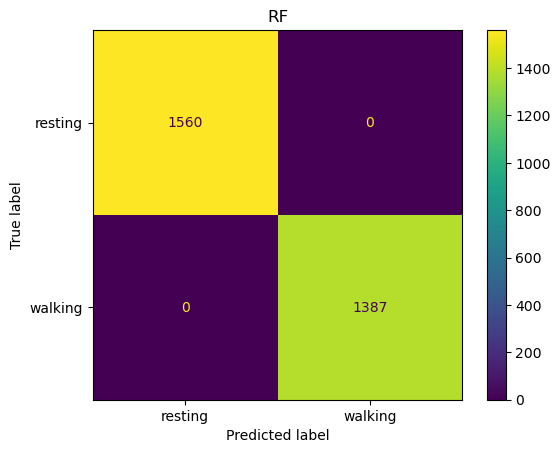

===== LogReg =====
              precision    recall  f1-score   support

     resting       1.00      1.00      1.00      1560
     walking       1.00      1.00      1.00      1387

    accuracy                           1.00      2947
   macro avg       1.00      1.00      1.00      2947
weighted avg       1.00      1.00      1.00      2947



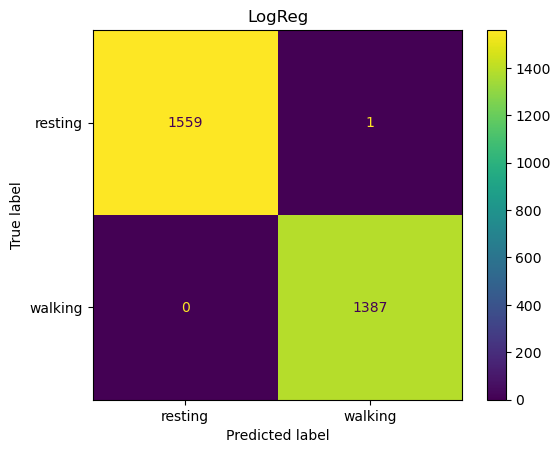

389    0.099917
83     0.099890
95     0.099698
381    0.050439
393    0.050138
403    0.049940
9      0.049917
344    0.049904
99     0.049890
181    0.049808
dtype: float64


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# 1 = walking group, 0 = resting group
merge = {1: 1, 2: 1, 3: 1,   # WALKING, UPSTAIRS, DOWNSTAIRS
         4: 0, 5: 0, 6: 0}   # SITTING, STANDING, LAYING
y_train2 = y_train.map(merge)
y_test2  = y_test.map(merge)
assert y_train2.isna().sum() == 0, "some labels didn't map - check they're 1-6 ints"

names = ['resting', 'walking']
models = {
    'RF':     RandomForestClassifier(n_estimators=20, max_depth=10, random_state=42),
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

for name, m in models.items():
    m.fit(X_train, y_train2)
    pred = m.predict(X_test)
    print(f'===== {name} =====')
    print(classification_report(y_test2, pred, target_names=names))
    ConfusionMatrixDisplay.from_predictions(y_test2, pred, display_labels=names)
    plt.title(name); plt.show()

# Which features is the RF actually using?
imp = pd.Series(models['RF'].feature_importances_, index=X_train.columns)
print(imp.sort_values(ascending=False).head(10))

### Final Model
After merging the labels into walking and resting, random forest classified every window correctly, and logreg made an error predicting a resting window as walking. The near-perfect scores are a sign that the task is easy, not that the data leaked. The trees in the forest were very small, using only 1-7 splits each, and 2 of the 20 trees used a single split, so a few thresholds were enough to separate the two classes. This fits how UCI-HAR was collected: scripted activities with the transitions between postures removed, which makes moving vs still very clean. Real wrist data from elderly users will be harder, because hand movement while sitting can look like walking. Because both models perform equally well, the choice between them comes down to how easy each is to run on the ESP32, and a simple threshold on acceleration is worth testing as an even lighter option.

These results come from the 561 precomputed features, scored on the official test set. The smaller forest below is the one exported for the ESP32. It uses the 24 window features instead and is scored on subjects 26-30, so its accuracy is not directly comparable with the results above.

In [13]:
from sklearn.ensemble import RandomForestClassifier

y_tr2 = y_tr.map(merge)
y_te2 = y_te.map(merge)

rf_small = RandomForestClassifier(n_estimators=10, max_depth=5, random_state=42)
rf_small.fit(X_tr, y_tr2)
print('Accuracy:', rf_small.score(X_te, y_te2))

Accuracy: 1.0


In [14]:
import emlearn
cmodel = emlearn.convert(rf_small, method='inline', dtype='float')   # keep dtype='float'
cmodel.save(file='har_model.h', name='har_model')

print(list(X_tr.columns))   # the exact feature order the ESP32 must follow

['acc_x_mean', 'acc_x_std', 'acc_x_min', 'acc_x_max', 'acc_y_mean', 'acc_y_std', 'acc_y_min', 'acc_y_max', 'acc_z_mean', 'acc_z_std', 'acc_z_min', 'acc_z_max', 'gyro_x_mean', 'gyro_x_std', 'gyro_x_min', 'gyro_x_max', 'gyro_y_mean', 'gyro_y_std', 'gyro_y_min', 'gyro_y_max', 'gyro_z_mean', 'gyro_z_std', 'gyro_z_min', 'gyro_z_max']


## Deep learning using CNN and LSTM (not yet)

## Choosing final model (not yet)

## Magnitude-only model (for testing on HAR70+)
HAR70+ has no gyroscope and its sensors face a different way, so this model only uses the **size (magnitude)** of the acceleration.
Features per window: mean, std, min, max and range of the magnitude. Labels are merged into walking (1) vs resting (0).

In [15]:
from features import magnitude, mag_features, FEATURE_NAMES
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

def load_total_acc(split):
    # each file has one row per window and 128 columns (samples)
    folder = path / split / 'Inertial Signals'
    return [pd.read_csv(folder / f'total_acc_{axis}_{split}.txt', sep=r'\s+', header=None).to_numpy()
            for axis in 'xyz']

# 1. magnitude of every window, then 5 features per window
ax, ay, az = load_total_acc('train')
X_train_mag = mag_features(magnitude(ax, ay, az))
ax, ay, az = load_total_acc('test')
X_test_mag = mag_features(magnitude(ax, ay, az))

# 2. merge the 6 activities into 2: 1,2,3 -> walking (1)   4,5,6 -> resting (0)
to_two = {1: 1, 2: 1, 3: 1, 4: 0, 5: 0, 6: 0}
y_train_mag = y_train.map(to_two)
y_test_mag = y_test.map(to_two)

print(X_train_mag.shape, X_test_mag.shape)   # one row per window, 5 columns

(7352, 5) (2947, 5)


In [16]:
# 3. train a small forest and check it on the official UCI test split
rf_mag = RandomForestClassifier(n_estimators=10, max_depth=5, random_state=42)
rf_mag.fit(X_train_mag, y_train_mag)

pred_mag = rf_mag.predict(X_test_mag)
print(classification_report(y_test_mag, pred_mag, target_names=['resting', 'walking']))

# which of the 5 features matter most?
print(pd.Series(rf_mag.feature_importances_, index=FEATURE_NAMES).round(3))

# 4. save the model so the HAR70+ notebook can load it
joblib.dump(rf_mag, 'rf_mag_uci.joblib')
print('saved rf_mag_uci.joblib')

              precision    recall  f1-score   support

     resting       1.00      1.00      1.00      1560
     walking       1.00      1.00      1.00      1387

    accuracy                           1.00      2947
   macro avg       1.00      1.00      1.00      2947
weighted avg       1.00      1.00      1.00      2947

mag_mean     0.000
mag_std      0.400
mag_min      0.099
mag_max      0.300
mag_range    0.200
dtype: float64
saved rf_mag_uci.joblib


In [17]:
print(cmodel)